# The `anb` testbed

A tour of the package API in three parts:

1. **One run.** Build a `ModelSpec` (what to simulate) and a `TestbedConfig` (the experiment protocol), run
   one seed and plot the focal belief and a few metrics over time.
2. **A small ensemble.** Run several seeds with `Testbed.run_ensemble` and read off the response frequencies
   (compliant, resilient, resistant, …).
3. **A new network.** Define a toy `Network` subclass right here, implementing only `build`, and run it through
   the same testbed.

The model is described in `docu/README.md`; the design is in `docu/adr-002-testbed-architecture.md`. This
notebook is a demo, not a sweep runner: large sweeps belong in a script.

In [9]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anb.agents import ANBAgent
from anb.metrics import RESPONSE_COLUMNS
from anb.model import ModelSpec
from anb.networks import ErdosRenyiNetwork, Network
from anb.testbed import PressureSchedule, Testbed, TestbedConfig

# Series colours in a fixed order: the first network is always blue, the second orange, and so on.
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## 1. One run

A `ModelSpec` bundles an **agent type** (the update rule and its parameters), a **network class** plus the
keyword arguments for its `build`, the population size and the social weight `rho`. It is a factory: every
run calls `spec.build(rng)` to get a fresh model from that run's own random generator.

Here: the paper's fully adaptive setting (`eps = 1`, `init_w = 0.2`, `beta = 3`) on an Erdős–Rényi network with
an expected degree of about 10 (`link_prob = 10 / N`).

In [10]:
N_AGENTS = 100

agent = ANBAgent(beta=3.0, eps=1.0, mu=0.0, init_w=0.2)
spec = ModelSpec(
    agent=agent,
    network_cls=ErdosRenyiNetwork,
    network_kwargs={"link_prob": 10 / N_AGENTS},
    n_agents=N_AGENTS,
    rho=1 / 3,
)
spec.params()

{'link_prob': 0.1,
 'beta': 3.0,
 'eps': 1.0,
 'mu': 0.0,
 'lam': 0.0,
 'init_w': 0.2,
 'rho': 0.3333333333333333,
 'fixedBNat100': False}

A `TestbedConfig` is the protocol. The `PressureSchedule` says how strong the external pressure is and when it
acts (`single_event` is the paper's t = 101…150). Everything else follows from it: the run length `T`, the
analysis windows and which steps get recorded. `detail=True` records every step, which is what we want for a
time series.

In [11]:
config = TestbedConfig(PressureSchedule.single_event(strength=4.0), detail=True)
print("T =", config.T)
config.windows()

T = 200


{'before': range(91, 101), 'during': range(141, 151), 'after': range(191, 201)}

In [12]:
result = Testbed(spec, config).run(seed=0)
result.frame.head()

,t,id,n_nbs,Hpers,Hpersfoc,Hsoc,Hext,tb_tot,tb_foc,absOm_tot,...,w56,w57,w58,w59,w67,w68,w69,w78,w79,w89
0,0,0,6.0,-0.306,0.490,0.027222,0.0,120.0,36.0,0.2,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2
1,0,1,9.0,-1.538,-0.240,0.015556,0.0,120.0,36.0,0.2,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2
2,0,2,5.0,0.404,0.090,0.040000,-0.0,120.0,36.0,0.2,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2
3,0,3,9.0,-0.180,0.448,-0.005185,0.0,120.0,36.0,0.2,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2
4,0,4,11.0,-0.802,-0.132,0.000606,-0.0,120.0,36.0,0.2,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2


`result.frame` has one row per agent and recorded step: `t`, `id`, the 14 metrics, the response dummies
(filled in at t = T in detail mode), the 10 beliefs and the 45 edge weights. Below: the focal belief and three
other metrics: the population mean with the interquartile range shaded, and the pressure event in grey. Focal
beliefs are bimodal, so the top panel also shows a few single agents.

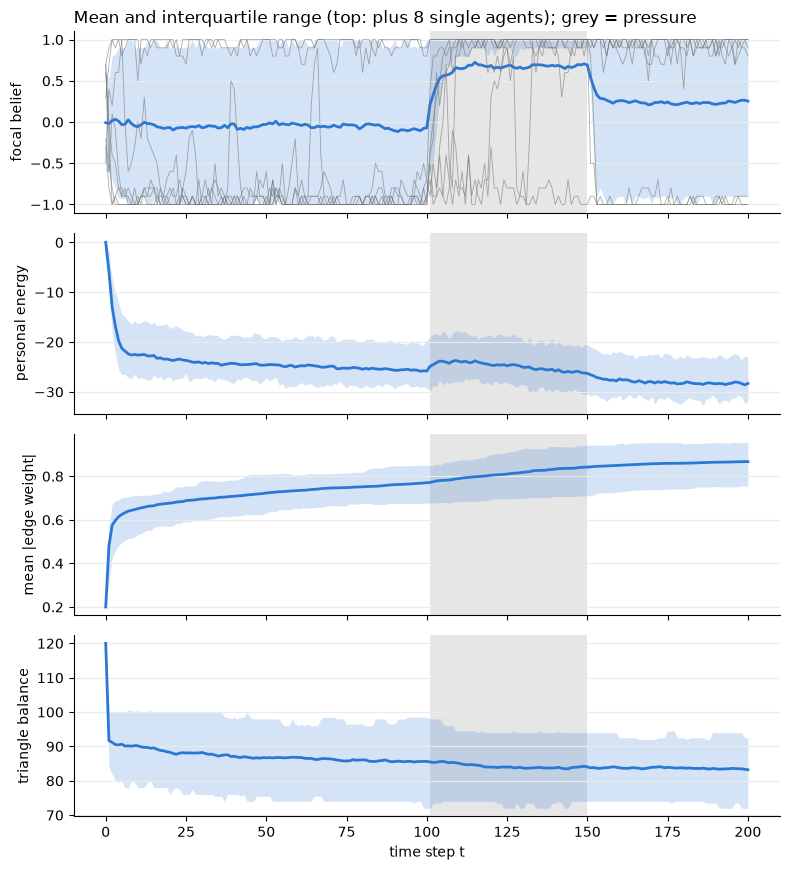

In [13]:
def plot_over_time(frame, columns, events, n_traces=8, colour="#2a78d6"):
    # One panel per metric: population mean (line) and interquartile range (band). The first panel also
    # shows a few individual agents as thin lines.
    fig, axes = plt.subplots(len(columns), 1, figsize=(8, 2.2 * len(columns)), sharex=True)
    by_t = frame.groupby("t")[list(columns)]
    mean, q25, q75 = by_t.mean(), by_t.quantile(0.25), by_t.quantile(0.75)
    for ax, (column, label) in zip(axes, columns.items()):
        for start, end in events:
            ax.axvspan(start, end, color="0.9", lw=0)
        ax.fill_between(mean.index, q25[column], q75[column], color=colour, alpha=0.2, lw=0)
        ax.plot(mean.index, mean[column], color=colour, lw=2)
        ax.set_ylabel(label)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="0.92")
    traces = frame[frame.id < n_traces].pivot(index="t", columns="id", values=next(iter(columns)))
    axes[0].plot(traces.index, traces, color="0.45", lw=0.6, alpha=0.6)
    axes[-1].set_xlabel("time step t")
    axes[0].set_title(f"Mean and interquartile range (top: plus {n_traces} single agents); grey = pressure",
                      loc="left")
    fig.tight_layout()
    return fig


plot_over_time(
    result.frame,
    {
        "x_focal": "focal belief",
        "Hpers": "personal energy",
        "absOm_tot": "mean |edge weight|",
        "tb_tot": "triangle balance",
    },
    config.schedule.events,
)
plt.show()

## 2. A small ensemble

For response frequencies we don't need every step. With the default `detail=False` each run keeps only the
snapshot steps plus one per-agent mean row per analysis window (t = 95.5, 145.5, 195.5), the same layout as
legacy `ANBmodel.py`. Each agent's response class sits on its t = 95.5 row.

`run_ensemble` runs one seed per job with joblib; every job builds its own model from its own seed.

In [14]:
SEEDS = range(10)
ensemble_config = TestbedConfig(PressureSchedule.single_event(strength=4.0))

er_results = Testbed(spec, ensemble_config).run_ensemble(SEEDS, n_jobs=-1)
sorted(er_results[0].frame.t.unique())

[np.float64(0.0),
 np.float64(95.5),
 np.float64(100.0),
 np.float64(145.5),
 np.float64(195.5),
 np.float64(200.0)]

In [15]:
def response_frequencies(results, config):
    # Share of agents in each response class, pooled over all seeds. The classes sit on the `before` window's
    # mean row, labelled with that window's midpoint (95.5 for the paper's protocol).
    t_before = np.mean(config.windows()["before"])
    rows = pd.concat([r.frame[r.frame.t == t_before] for r in results])
    return rows[list(RESPONSE_COLUMNS)].mean()


frequencies = pd.DataFrame({"Erdős–Rényi": response_frequencies(er_results, ensemble_config)})
frequencies.round(3)

,Erdős–Rényi
persistPos,0.44
nonpersistPos,0.015
compliant,0.157
resilient,0.234
resistant,0.154
latecompliant,0.0


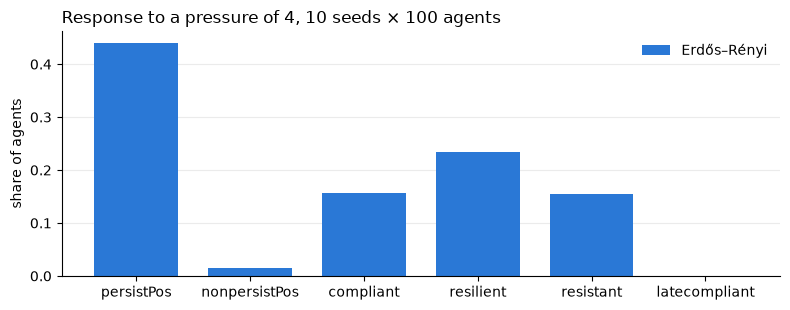

In [16]:
def plot_frequencies(frequencies, title):
    fig, ax = plt.subplots(figsize=(8, 3.2))
    width = 0.8 / frequencies.shape[1]
    x = np.arange(len(frequencies))
    for k, name in enumerate(frequencies):
        ax.bar(x + (k - (frequencies.shape[1] - 1) / 2) * width, frequencies[name], width * 0.92,
               color=COLOURS[k], label=name)
    ax.set_xticks(x, frequencies.index)
    ax.set_ylabel("share of agents")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.92")
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    ax.set_title(title, loc="left")
    fig.tight_layout()
    return fig


FREQUENCY_TITLE = (f"Response to a pressure of {ensemble_config.schedule.strength:g}, "
                   f"{len(SEEDS)} seeds × {N_AGENTS} agents")
plot_frequencies(frequencies, FREQUENCY_TITLE)
plt.show()

To feed the legacy analysis scripts, `result.save(".")` writes each run with the same columns as `ANBmodel.py`
(`result.to_frame()` shows them) under the `../simOut_old_model` filename it would use. Legacy names only exist for the
paper's Erdős–Rényi setup; for any other network use `result.save(directory, legacy_names=False)`. We don't
write files here.

## 3. A new network in a few lines

A network is a class with one classmethod, `build(n_agents, rng, **kwargs)`, that returns an instance holding an
`(N, N)` adjacency matrix. The base class already stores the matrix and provides `n_agents`, `neighbours` and
`degree`, so a subclass only has to build it.

The toy example: a ring lattice, where each agent is linked to its `k` nearest neighbours on each side. With
`k = 5` every agent has degree 10, about the mean degree of the Erdős–Rényi network above, but the links are
local and highly clustered. It's deterministic, so it ignores `rng`.

In [17]:
class RingLattice(Network):
    """Agents on a ring, each linked to its `k` nearest neighbours on either side (degree 2k)."""

    @classmethod
    def build(cls, n_agents, rng, k):
        index_gap = np.abs(np.subtract.outer(np.arange(n_agents), np.arange(n_agents)))
        ring_distance = np.minimum(index_gap, n_agents - index_gap)
        return cls(((ring_distance >= 1) & (ring_distance <= k)).astype(float))


ring = RingLattice.build(N_AGENTS, np.random.default_rng(0), k=5)
print("degrees:", set(ring.degree()), "| neighbours of agent 0:", ring.neighbours(0))

degrees: {np.int64(10)} | neighbours of agent 0: [ 1  2  3  4  5 95 96 97 98 99]


That's the whole extension. Swap it into the spec and run the same protocol, unchanged:

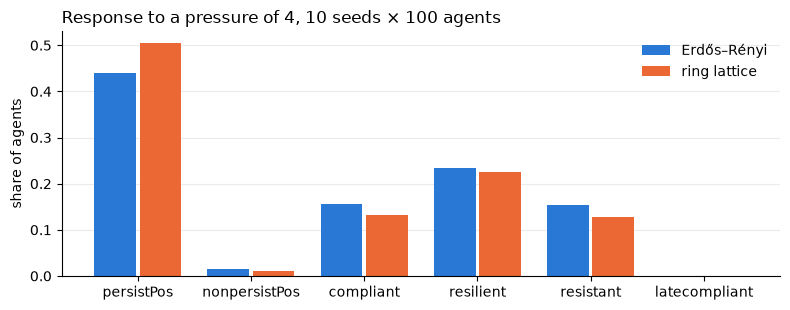

,Erdős–Rényi,ring lattice
persistPos,0.44,0.505
nonpersistPos,0.015,0.011
compliant,0.157,0.132
resilient,0.234,0.225
resistant,0.154,0.127
latecompliant,0.0,0.0


In [18]:
ring_spec = dataclasses.replace(spec, network_cls=RingLattice, network_kwargs={"k": 5})
ring_results = Testbed(ring_spec, ensemble_config).run_ensemble(SEEDS, n_jobs=-1)

frequencies["ring lattice"] = response_frequencies(ring_results, ensemble_config)
plot_frequencies(frequencies, FREQUENCY_TITLE)
plt.show()
frequencies.round(3)

The same works for agents and metrics: subclass `Agent` (the update rule, one `sweep` per time step) or
`Metric` (one `compute(ctx)` returning a value per agent), and pass it to `ModelSpec` or `Testbed(...,
metrics=[...])`. See `docu/class-design.md`.